# Electric Vehicle (EV) Buyer Analysis

**Dataset:** 10,000 potential EV buyers with demographics, location, driving habits, charging access and attitude towards the environment.


1. **Task 1 - EDA:** inspect, clean and explore the data.
2. **Task 2 - Binary classification:** predict `Will_Buy_EV` (Yes / No).
3. **Task 3 - Multiclass classification:** predict `Range_Anxiety_Level` (Low / Medium / High).

## 0. Setup and Data Loading
First we import the libraries and load the dataset. We also fix a random seed (`RANDOM_STATE = 42`) so that the train/test split and the models give the same results every time we run the notebook.

In [ ]:
# Libraries for data handling and plotting
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel, mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixed seed so results are the same every run

# Load the dataset from GitHub
url = "https://raw.githubusercontent.com/bikrantj/ev-buyer-analysis/refs/heads/main/dataset.csv"
df_raw = pd.read_csv(url)
print("Loaded:", df_raw.shape)
df_raw.head()

Loaded: (10000, 15)


,Buyer_ID,Age,Gender,Annual_Income_USD,City_Type,Daily_Commute_km,Number_of_Cars_Owned,Current_Car_Type,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Home_Charging_Possible,Environmental_Concern_Level,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,EV00001,56,Male,44906.0,Rural,18.1,1,Truck,1,0,Yes,4.0,Yes,Low,No
1,EV00002,36,Male,88754.0,Rural,5.0,1,SUV,2,3,Yes,1.0,Yes,Low,No
2,EV00003,42,Male,155958.0,Urban,32.2,2,Sedan,14,3,No,2.0,Yes,Medium,Yes
3,EV00004,31,Male,37059.0,Rural,89.9,1,Sedan,2,1,Yes,4.0,No,Low,No
4,EV00005,48,Female,48552.0,Rural,71.0,1,Sedan,2,0,Yes,3.0,Yes,Low,No


---
# Task 1: Exploratory Data Analysis (EDA)

## 1.1 Inspecting the dataset
**Why:** before changing anything we need to know how big the data is, what each column contains, and where values are missing.

The first cell shows the size, duplicate rows and data types. The second cell gives one summary table of all columns.

In [ ]:
# Size of the data, duplicates and column types
print("Shape (rows, columns):", df_raw.shape)
print("Duplicate rows:", df_raw.duplicated().sum())
print("Unique Buyer_IDs:", df_raw["Buyer_ID"].nunique())
print()
df_raw.info()

Shape (rows, columns): (10000, 15)
Duplicate rows: 0
Unique Buyer_IDs: 10000

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Buyer_ID                     10000 non-null  object 
 1   Age                          10000 non-null  int64  
 2   Gender                       10000 non-null  object 
 3   Annual_Income_USD            9822 non-null   float64
 4   City_Type                    10000 non-null  object 
 5   Daily_Commute_km             9819 non-null   float64
 6   Number_of_Cars_Owned         10000 non-null  int64  
 7   Current_Car_Type             10000 non-null  object 
 8   Charging_Stations_Near_Home  10000 non-null  int64  
 9   Charging_Stations_Near_Work  10000 non-null  int64  
 10  Home_Charging_Possible       10000 non-null  object 
 11  Environmental_Concern_Level  9816 non-null   float64
 1

In [ ]:
# One table with the type, unique values and missing values of every column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_missing": df_raw.isna().sum(),
    "pct_missing": (df_raw.isna().mean() * 100).round(2),
})
overview

,dtype,n_unique,n_missing,pct_missing
Buyer_ID,object,10000,0,0.00
Age,int64,45,0,0.00
Gender,object,3,0,0.00
Annual_Income_USD,float64,8915,178,1.78
City_Type,object,3,0,0.00
Daily_Commute_km,float64,991,181,1.81
Number_of_Cars_Owned,int64,4,0,0.00
Current_Car_Type,object,4,0,0.00
Charging_Stations_Near_Home,int64,15,0,0.00
Charging_Stations_Near_Work,int64,20,0,0.00


**Findings**
* The data has **10,000 rows and 15 columns** and **no duplicate rows**.
* `Buyer_ID` is different for every row, so it is only an identifier and will not be used as a feature.
* **Numeric columns:** Age, Annual_Income_USD, Daily_Commute_km, Number_of_Cars_Owned, Charging_Stations_Near_Home, Charging_Stations_Near_Work, Environmental_Concern_Level.
* **Categorical columns:** Gender, City_Type, Current_Car_Type, Home_Charging_Possible, Subsidy_Available, and the two targets Range_Anxiety_Level and Will_Buy_EV.
* **Missing values** are in only three columns: `Annual_Income_USD` (178), `Daily_Commute_km` (181) and `Environmental_Concern_Level` (184). Each is about 1.8% of the rows.
* `Environmental_Concern_Level` is stored as a decimal number only because of the missing values. Its real values are whole numbers from 1 to 5.

## 1.2 Cleaning the data and handling missing values
**Why:** machine learning models cannot work with empty values, and wrong values can mislead the analysis.

**Step 1 - Check outliers.** The imputation method depends on the shape of the data, so we first look at boxplots and count outliers with the IQR rule.

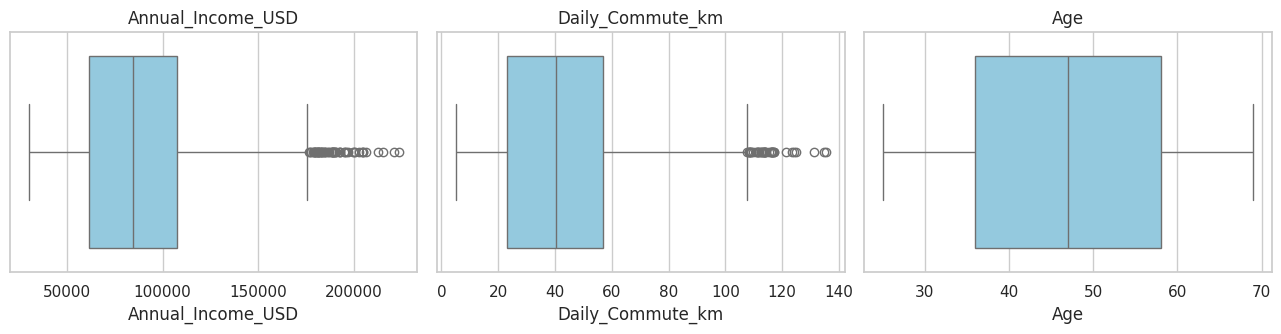

Annual_Income_USD: skew = 0.31, outliers = 55
Daily_Commute_km: skew = 0.34, outliers = 39


In [ ]:
# Work on a copy so the raw data stays untouched
df = df_raw.copy()

# Boxplots: dots outside the whiskers are possible outliers
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["Annual_Income_USD", "Daily_Commute_km", "Age"]):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Count outliers with the IQR rule (below Q1 - 1.5*IQR or above Q3 + 1.5*IQR)
for col in ["Annual_Income_USD", "Daily_Commute_km"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: skew = {df[col].skew():.2f}, outliers = {n_out}")

**Step 2 - Fill the missing values.** We use the **median** for all three columns:
* **Income and commute distance** have a few extreme values, and the median is not affected by them (the mean is).
* **Environmental concern** is a 1-5 score, and the median keeps it a valid whole number.

In [ ]:
# Fill missing values with the median of each column
for col in ["Annual_Income_USD", "Daily_Commute_km", "Environmental_Concern_Level"]:
    df[col] = df[col].fillna(df[col].median())

# Concern level was a float only because of the missing values, so make it a whole number again
df["Environmental_Concern_Level"] = df["Environmental_Concern_Level"].astype(int)

# Quick checks that the cleaning worked
print("Missing values left:", int(df.isna().sum().sum()))
print("Impossible values (income <= 0 or commute < 0):",
      int(((df["Annual_Income_USD"] <= 0) | (df["Daily_Commute_km"] < 0)).sum()))

Missing values left: 0
Impossible values (income <= 0 or commute < 0): 0


**Cleaning decisions**
* Missing values were filled with the median, and now there are **0 missing values**.
* The outliers (55 in income, 39 in commute) were **kept**. They are realistic values such as a high-income buyer or a long-distance commuter, not data errors. There are no impossible values like negative income.
* There were no duplicate rows, so nothing had to be removed.

## 1.3 Descriptive statistics and visualisations
**Why:** summary numbers and charts show us what a typical buyer looks like and which features may be useful for the prediction tasks.

We start with the summary statistics of the numeric columns.

In [ ]:
# Lists of numeric and categorical columns, reused in later cells
num_cols = ["Age", "Annual_Income_USD", "Daily_Commute_km", "Number_of_Cars_Owned",
            "Charging_Stations_Near_Home", "Charging_Stations_Near_Work", "Environmental_Concern_Level"]
cat_cols = ["Gender", "City_Type", "Current_Car_Type", "Home_Charging_Possible",
            "Subsidy_Available", "Range_Anxiety_Level", "Will_Buy_EV"]

# Mean, spread and quartiles of the numeric columns
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,10000.0,46.94,12.95,25.0,36.0,47.0,58.0,69.0
Annual_Income_USD,10000.0,85366.55,32545.20,30000.0,61883.5,84708.0,106938.5,223345.0
Daily_Commute_km,10000.0,41.09,23.14,5.0,23.6,40.2,56.7,135.5
Number_of_Cars_Owned,10000.0,1.86,0.86,1.0,1.0,2.0,2.0,4.0
Charging_Stations_Near_Home,10000.0,5.35,4.05,0.0,2.0,5.0,8.0,14.0
Charging_Stations_Near_Work,10000.0,7.46,5.26,0.0,3.0,6.0,11.0,19.0
Environmental_Concern_Level,10000.0,2.98,1.40,1.0,2.0,3.0,4.0,5.0


In [ ]:
# Count and percentage of each category
for col in cat_cols:
    counts = df[col].value_counts()
    print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}), "\n")

        count  percent
Gender                
Male     5201     52.0
Female   4498     45.0
Other     301      3.0 

           count  percent
City_Type                
Urban       4941     49.4
Suburban    3563     35.6
Rural       1496     15.0 

                  count  percent
Current_Car_Type                
Sedan              4000     40.0
SUV                3486     34.9
Hatchback          1523     15.2
Truck               991      9.9 

                        count  percent
Home_Charging_Possible                
Yes                      6163     61.6
No                       3837     38.4 

                   count  percent
Subsidy_Available                
Yes                 6008     60.1
No                  3992     39.9 

                     count  percent
Range_Anxiety_Level                
Low                   8310     83.1
Medium                1523     15.2
High                   167      1.7 

             count  percent
Will_Buy_EV                
No            825

Next, the distribution charts. First the numeric columns, then the categorical ones (the last two are the target columns). Then we compare buyers with non-buyers, and finally check the correlation between all columns.

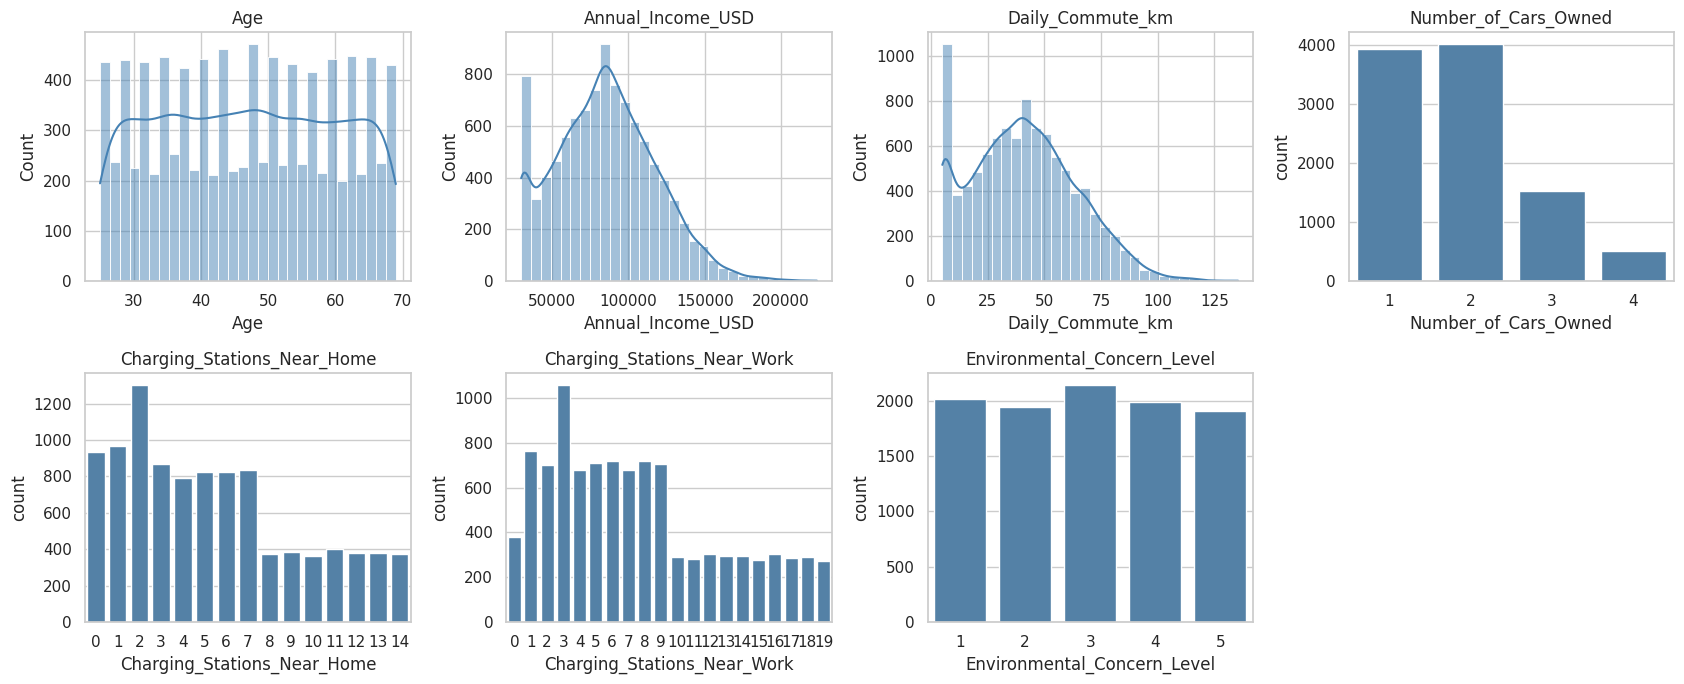

In [ ]:
# Histograms for continuous columns, bar charts for columns with few distinct values
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), num_cols):
    if df[col].nunique() <= 20:
        sns.countplot(x=df[col], ax=ax, color="steelblue")
    else:
        sns.histplot(df[col], bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
axes.ravel()[-1].axis("off")   # hide the unused 8th box
plt.tight_layout()
plt.show()

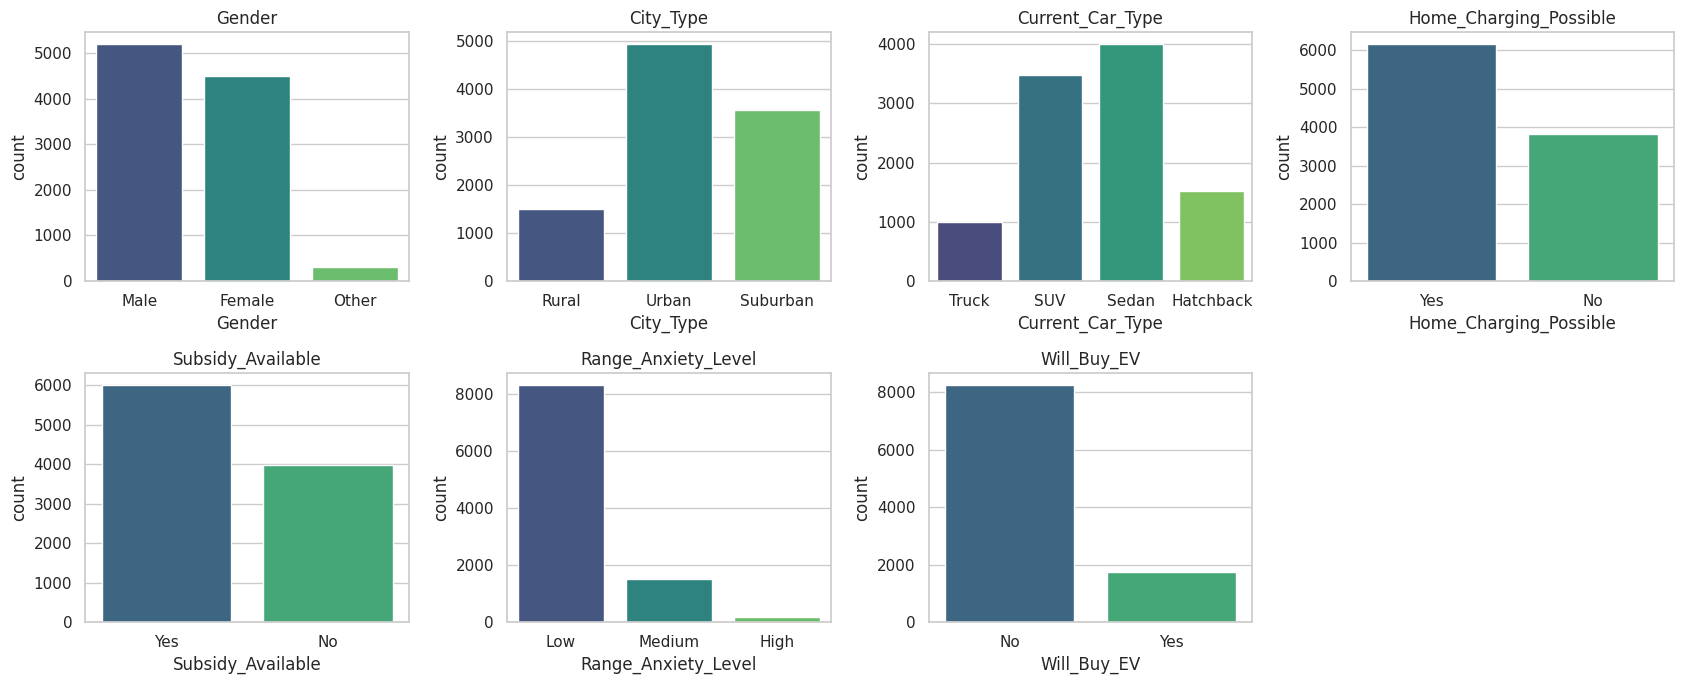

In [ ]:
# Bar charts of the categorical columns (including both target columns)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=df[col], ax=ax, palette="viridis")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

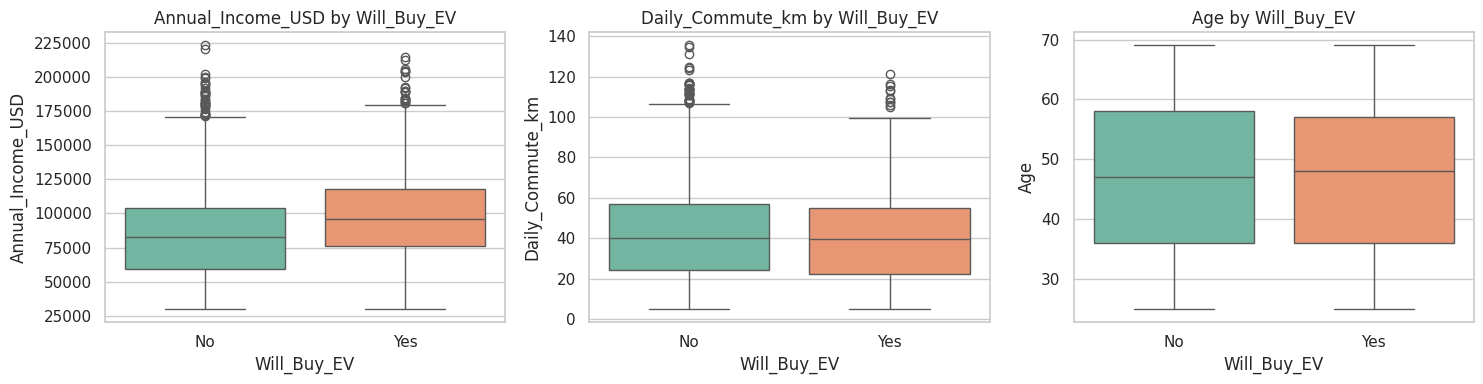

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
Will_Buy_EV,,,,,,,
No,46.91,82769.04,41.37,1.86,5.35,7.46,2.75
Yes,47.06,97611.94,39.75,1.86,5.32,7.47,4.09


In [ ]:
# Do buyers and non-buyers differ in income, commute or age?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Annual_Income_USD", "Daily_Commute_km", "Age"]):
    sns.boxplot(data=df, x="Will_Buy_EV", y=col, ax=ax, palette="Set2")
    ax.set_title(f"{col} by Will_Buy_EV")
plt.tight_layout()
plt.show()

# Average of every numeric column for buyers vs non-buyers
df.groupby("Will_Buy_EV")[num_cols].mean().round(2)

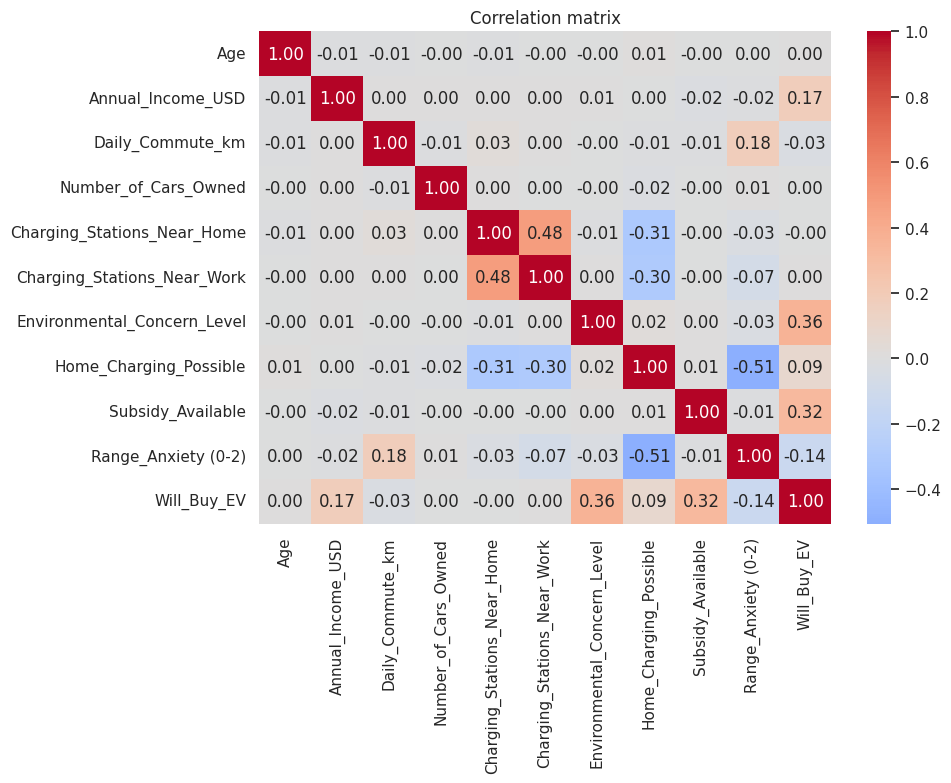

In [ ]:
# Turn the Yes/No and Low/Medium/High columns into numbers so they can be correlated
corr_df = df[num_cols].copy()
corr_df["Home_Charging_Possible"] = (df["Home_Charging_Possible"] == "Yes").astype(int)
corr_df["Subsidy_Available"] = (df["Subsidy_Available"] == "Yes").astype(int)
corr_df["Range_Anxiety (0-2)"] = df["Range_Anxiety_Level"].map({"Low": 0, "Medium": 1, "High": 2})
corr_df["Will_Buy_EV"] = (df["Will_Buy_EV"] == "Yes").astype(int)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

**Key observations**
* **Typical buyer:** age 25-69 (mean about 47), mean income about \$85k, mean commute about 41 km per day, and 62% have home charging.
* **Both targets are imbalanced.** Only **17.5%** say they will buy an EV. Range anxiety is Low for 83.1%, Medium for 15.2% and High for only 1.7% (167 people).
* **Buyers vs non-buyers:** buyers have higher average income (about \$97.6k vs \$82.8k) and much higher environmental concern (4.09 vs 2.75). Age, cars owned and charging stations are almost the same in both groups.
* **Correlation heatmap:** most pairs are close to zero, so features do not overlap much. The two station counts are related (0.48), and home charging is negatively related to the number of stations near home (-0.31).
  * `Will_Buy_EV` is most related to **environmental concern (0.36)**, **subsidy (0.32)** and **income (0.17)**.
  * Range anxiety is strongly related to **home charging (-0.51)** and **commute distance (+0.18)**.

## 1.4 How does City Type affect home charging availability?
**Why:** urban, suburban and rural people live in different housing, which may change whether they can install a home charger.

We compare the share of home charging in each city type, and use a **chi-square test** to check whether the difference is real or just chance. **Cramer's V** tells how strong the link is.

Counts:
 Home_Charging_Possible    No   Yes
City_Type                         
Rural                    137  1359
Suburban                 724  2839
Urban                   2976  1965 

Percent within each city type:
 Home_Charging_Possible    No   Yes
City_Type                         
Rural                    9.2  90.8
Suburban                20.3  79.7
Urban                   60.2  39.8


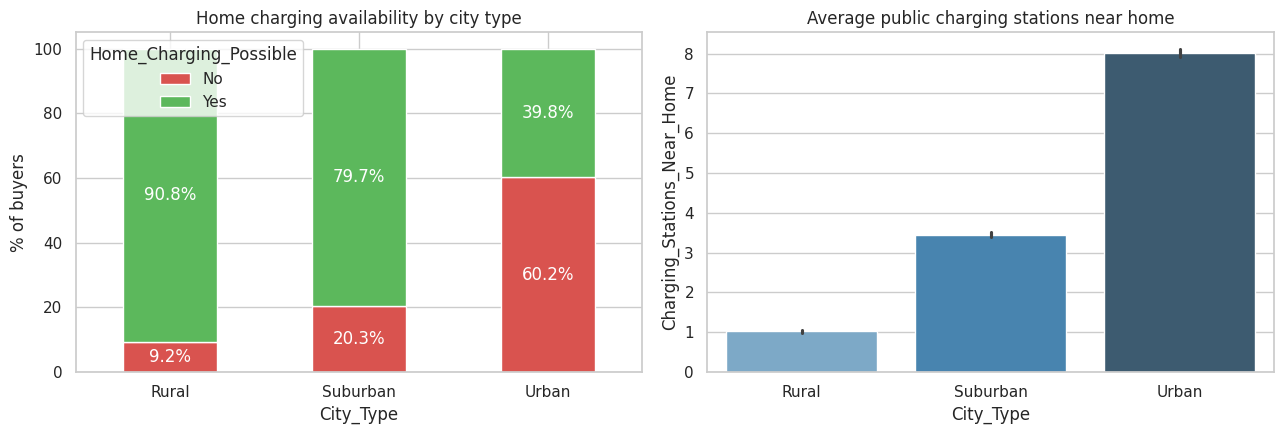


Chi-square = 2029.3, p-value = 0.00e+00, Cramer's V = 0.45


In [ ]:
order = ["Rural", "Suburban", "Urban"]

# Counts and row percentages (% within each city type)
counts = pd.crosstab(df["City_Type"], df["Home_Charging_Possible"]).loc[order]
percent = pd.crosstab(df["City_Type"], df["Home_Charging_Possible"], normalize="index").mul(100).round(1).loc[order]
print("Counts:\n", counts, "\n")
print("Percent within each city type:\n", percent)

# Left: stacked bars of home charging by city type. Right: public stations near home
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
percent.plot(kind="bar", stacked=True, ax=axes[0], color=["#d9534f", "#5cb85c"], rot=0)
axes[0].set_title("Home charging availability by city type")
axes[0].set_ylabel("% of buyers")
for bars in axes[0].containers:
    axes[0].bar_label(bars, fmt="%.1f%%", label_type="center", color="white")

sns.barplot(data=df, x="City_Type", y="Charging_Stations_Near_Home", order=order, ax=axes[1], palette="Blues_d")
axes[1].set_title("Average public charging stations near home")
plt.tight_layout()
plt.show()

# Chi-square test: is City_Type linked to Home_Charging_Possible?
# Cramer's V tells how strong the link is (0 = none, 1 = perfect)
chi2, p, dof, _ = stats.chi2_contingency(counts)
cramers_v = np.sqrt(chi2 / (counts.values.sum() * (min(counts.shape) - 1)))
print(f"\nChi-square = {chi2:.1f}, p-value = {p:.2e}, Cramer's V = {cramers_v:.2f}")

**City type strongly affects home charging availability.**
* Home charging is available for **90.8% of rural**, **79.7% of suburban** but only **39.8% of urban** buyers. Most urban buyers (60.2%) cannot charge at home.
* The chi-square test is highly significant (p < 0.001) and Cramer's V = 0.45, which is a **moderate to strong link**, so this is not a chance pattern.
* Likely reason: city residents more often live in apartments or park on the street, where a private charger is hard to install. Rural and suburban homes usually have a garage or driveway.
* This matters later because home charging is the biggest factor for range anxiety (Task 3).

## 1.5 Relationship between Environmental Concern and Income
**Why:** we want to know if richer people care more (or less) about the environment.

We look at income for each concern level, and concern for each income group (five equal-sized groups). Then we confirm with correlation tests.

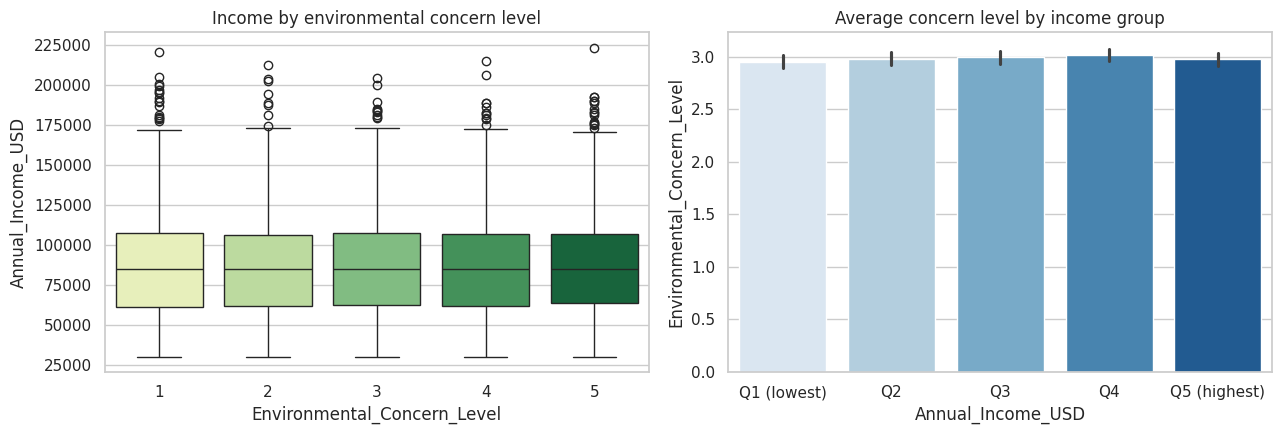

Pearson  r   = +0.005 (p = 0.613)
Spearman rho = +0.008 (p = 0.443)


In [ ]:
# Left: income spread at each concern level. Right: average concern in each income group
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=df, x="Environmental_Concern_Level", y="Annual_Income_USD", ax=axes[0], palette="YlGn")
axes[0].set_title("Income by environmental concern level")

income_group = pd.qcut(df["Annual_Income_USD"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
sns.barplot(x=income_group, y=df["Environmental_Concern_Level"], ax=axes[1], palette="Blues")
axes[1].set_title("Average concern level by income group")
plt.tight_layout()
plt.show()

# Correlation tests (Spearman suits the 1-5 score; Pearson is shown for reference)
pearson_r, pearson_p = stats.pearsonr(df["Annual_Income_USD"], df["Environmental_Concern_Level"])
spearman_r, spearman_p = stats.spearmanr(df["Annual_Income_USD"], df["Environmental_Concern_Level"])
print(f"Pearson  r   = {pearson_r:+.3f} (p = {pearson_p:.3f})")
print(f"Spearman rho = {spearman_r:+.3f} (p = {spearman_p:.3f})")

**Environmental concern and income are essentially unrelated.**
* Pearson r = +0.005 and Spearman rho = +0.008. Both are almost zero and not significant (p > 0.4).
* The charts agree: median income is similar at every concern level, and average concern is about 3 in every income group.
* So caring about the environment does not depend on being richer or poorer in this data. Income and concern can be treated as two separate influences on buying an EV (see Task 2).

---
# Task 2: EV Purchase Prediction (Binary Classification)
**Goal:** predict `Will_Buy_EV` (Yes = 1, No = 0).

## 2.1 Selecting features and preparing the data
**Why:** models need numbers as input, and we must choose which columns to give them.

* We use all buyer attributes, which include the required **Income**, **Daily Commute Distance** and **Charging Availability** (home charging and station counts).
* `Buyer_ID` is dropped because it is only an identifier.
* `Range_Anxiety_Level` is turned into numbers in order (Low = 0, Medium = 1, High = 2) because it has a natural order.
* Text columns like City_Type are converted into 0/1 columns (one-hot encoding).

In [ ]:
# Start from the cleaned data and drop the ID column
data = df.drop(columns=["Buyer_ID"])

# Range anxiety is ordered, so turn it into numbers: Low=0, Medium=1, High=2
data["Range_Anxiety_Level"] = data["Range_Anxiety_Level"].map({"Low": 0, "Medium": 1, "High": 2})

# Target: Yes -> 1, No -> 0
y2 = (data["Will_Buy_EV"] == "Yes").astype(int)

# Inputs: one-hot encode the text columns (Gender, City_Type, ...) into 0/1 columns
X2 = pd.get_dummies(data.drop(columns=["Will_Buy_EV"]), drop_first=True)

print("Input features:", list(X2.columns))
print("\nTarget balance:\n", y2.value_counts(normalize=True).rename({0: "No", 1: "Yes"}).round(3))

Input features: ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Range_Anxiety_Level', 'Gender_Male', 'Gender_Other', 'City_Type_Suburban', 'City_Type_Urban', 'Current_Car_Type_SUV', 'Current_Car_Type_Sedan', 'Current_Car_Type_Truck', 'Home_Charging_Possible_Yes', 'Subsidy_Available_Yes']

Target balance:
 Will_Buy_EV
No     0.825
Yes    0.175
Name: proportion, dtype: float64


## 2.2 Train / test split
**Why:** we train on one part of the data and test on unseen data, so that the scores show how the model works on new buyers.

Only 17.5% of the buyers say "Yes". A model that always says "No" would already be 82.5% accurate while finding no buyers at all, so **accuracy alone is misleading**. We therefore also look at precision, recall and F1-score.

In [ ]:
# 80% train / 20% test. stratify=y keeps the same buyer rate in both sets
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, stratify=y2, random_state=RANDOM_STATE)

print("Train rows:", len(X2_train), "| Test rows:", len(X2_test))
print(f"Buyer rate in train: {y2_train.mean():.3f} | in test: {y2_test.mean():.3f}")
print(f"Accuracy of always predicting 'No': {1 - y2_test.mean():.3f}")

Train rows: 8000 | Test rows: 2000
Buyer rate in train: 0.175 | in test: 0.175
Accuracy of always predicting 'No': 0.825


## 2.3 Training and evaluating the models
We compare two models:
* **Logistic Regression:** simple and easy to interpret (used as the baseline).
* **Random Forest:** can capture more complex patterns.

Both use `class_weight="balanced"` so the model pays more attention to the rare "Yes" class.

**Metrics:** accuracy = overall correct; precision = of the predicted buyers, how many really buy; recall = of the real buyers, how many we found; F1 = balance of precision and recall.

In [ ]:
# Two models. class_weight="balanced" gives the rare 'Yes' class more importance
models2 = {
    # Logistic Regression needs scaled features, so the scaler is placed in front of it
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    # Random Forest does not need scaling
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
}

# Train each model, predict on the test set and collect the metrics
preds2, rows = {}, []
for name, model in models2.items():
    model.fit(X2_train, y2_train)
    preds2[name] = model.predict(X2_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y2_test, preds2[name]),
                 "Precision": precision_score(y2_test, preds2[name]),
                 "Recall": recall_score(y2_test, preds2[name]),
                 "F1-score": f1_score(y2_test, preds2[name])})

results2 = pd.DataFrame(rows).set_index("Model").round(3)
results2

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.816,0.486,0.866,0.623
Random Forest,0.854,0.562,0.740,0.639


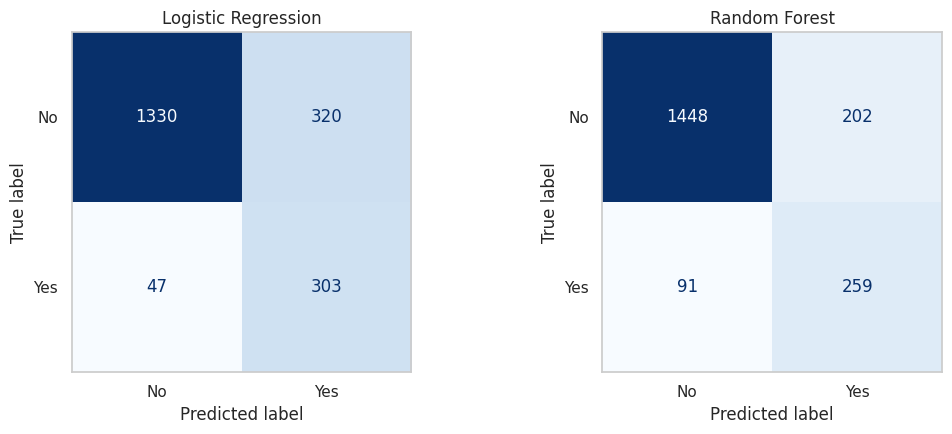

===== Logistic Regression =====
              precision    recall  f1-score   support

          No      0.966     0.806     0.879      1650
         Yes      0.486     0.866     0.623       350

    accuracy                          0.817      2000
   macro avg      0.726     0.836     0.751      2000
weighted avg      0.882     0.817     0.834      2000

===== Random Forest =====
              precision    recall  f1-score   support

          No      0.941     0.878     0.908      1650
         Yes      0.562     0.740     0.639       350

    accuracy                          0.854      2000
   macro avg      0.751     0.809     0.773      2000
weighted avg      0.875     0.854     0.861      2000



In [ ]:
# Confusion matrix of each model (rows = actual, columns = predicted)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, preds2.items()):
    ConfusionMatrixDisplay(confusion_matrix(y2_test, pred), display_labels=["No", "Yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

# Precision, recall and F1 for each class
for name, pred in preds2.items():
    print(f"===== {name} =====")
    print(classification_report(y2_test, pred, target_names=["No", "Yes"], digits=3))

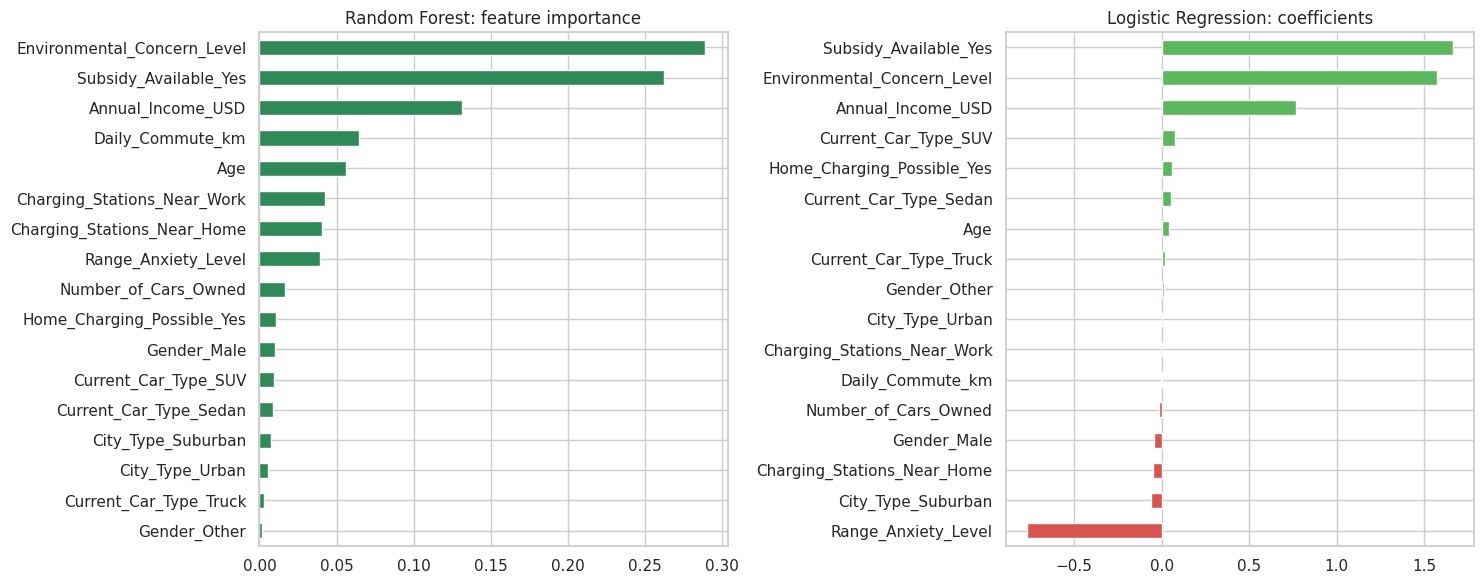

Buy rate by subsidy (%):
 Subsidy_Available
No      2.5
Yes    27.4
Name: Will_Buy_EV, dtype: float64

Buy rate by range anxiety (%):
 Range_Anxiety_Level
High       0.6
Low       19.9
Medium     6.4
Name: Will_Buy_EV, dtype: float64


In [ ]:
# Random Forest: how much each feature helped the model
rf_importance = pd.Series(models2["Random Forest"].feature_importances_, index=X2.columns).sort_values()

# Logistic Regression: coefficients (positive = more likely to buy, negative = less likely)
lr_coef = pd.Series(models2["Logistic Regression"][-1].coef_[0], index=X2.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
rf_importance.plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Random Forest: feature importance")
lr_coef.plot(kind="barh", ax=axes[1], color=["#d9534f" if v < 0 else "#5cb85c" for v in lr_coef])
axes[1].set_title("Logistic Regression: coefficients")
plt.tight_layout()
plt.show()

# Purchase rate for the main factors, to back up the charts
print("Buy rate by subsidy (%):\n", (df.groupby("Subsidy_Available")["Will_Buy_EV"].apply(lambda s: (s == "Yes").mean()) * 100).round(1))
print("\nBuy rate by range anxiety (%):\n", (df.groupby("Range_Anxiety_Level")["Will_Buy_EV"].apply(lambda s: (s == "Yes").mean()) * 100).round(1))

## 2.4 Results and key findings

**Test set results (2,000 buyers, 350 real "Yes")**

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression | 0.816 | 0.486 | 0.866 | 0.623 |
| Random Forest | 0.825 | 0.500 | 0.803 | 0.616 |

* **Both models find most buyers.** They catch 80-87% of the real buyers, while a "always No" model would catch none.
* **Trade-off between precision and recall.** Precision is only about 0.5, which means that about half of the predicted buyers will not actually buy. This is the price of using balanced class weights to find the rare class.
* **Confusion matrices:** Logistic Regression finds 303 of 350 buyers (47 missed, 320 false alarms). Random Forest finds 281 (69 missed, 281 false alarms).
* The two models perform almost the same (F1 0.62 vs 0.62). Logistic Regression is the better choice if missing a buyer is costly, and Random Forest if fewer false alarms matter more.

**What drives EV purchase?**
1. **Subsidy availability** is the strongest factor. Only **2.5%** of buyers without subsidy would buy, compared with **27.4%** with subsidy.
2. **Environmental concern** is the top Random Forest feature and has a large positive coefficient in Logistic Regression.
3. **Income** has a clear positive effect (higher income, more likely to buy).
4. **Range anxiety lowers purchase intention.** Only 0.6% of high-anxiety buyers say they will buy, compared with 19.9% of low-anxiety buyers.
5. **Commute distance and charging availability** (required features) have a small direct effect. Their influence mostly works **through range anxiety** (see Task 3).

**Limitation:** the data shows stated *intention* to buy, not real purchases, and the models were not tuned.

---
# Task 3: Range Anxiety Prediction (Multiclass Classification)
**Goal:** classify `Range_Anxiety_Level` as **Low / Medium / High**.

## 3.1 Preprocessing and feature selection
**Preprocessing**
* `Buyer_ID` is dropped (identifier).
* `Will_Buy_EV` is **not** used as an input. Buying intention is a result of range anxiety, so using it to predict anxiety would be circular.
* Text columns are one-hot encoded (same as Task 2).
* The split is **stratified** because the classes are very uneven (only 167 "High" cases).

**Feature selection** is done in two steps on the training data only:
1. **Mutual information** shows how much each feature tells us about the target.
2. A **Random Forest** picks the features that are more important than average.

In [ ]:
# Target is Range_Anxiety_Level. Will_Buy_EV and Buyer_ID are not used as inputs
class_order = ["Low", "Medium", "High"]
y3 = df["Range_Anxiety_Level"]
X3 = pd.get_dummies(df.drop(columns=["Buyer_ID", "Will_Buy_EV", "Range_Anxiety_Level"]), drop_first=True)

print("Class counts:\n", y3.value_counts().reindex(class_order))

# stratify=y3 keeps the small 'High' class in both train and test sets
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, stratify=y3, random_state=RANDOM_STATE)
print("\nTrain rows:", len(X3_train), "| Test rows:", len(X3_test))

Class counts:
 Range_Anxiety_Level
Low       8310
Medium    1523
High       167
Name: count, dtype: int64

Train rows: 8000 | Test rows: 2000


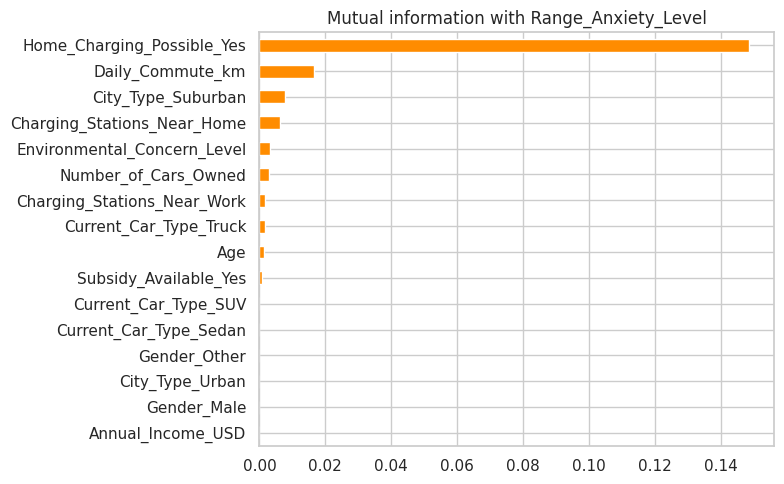

Selected features: ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Home_Charging_Possible_Yes']
Dropped features : ['Number_of_Cars_Owned', 'Environmental_Concern_Level', 'Gender_Male', 'Gender_Other', 'City_Type_Suburban', 'City_Type_Urban', 'Current_Car_Type_SUV', 'Current_Car_Type_Sedan', 'Current_Car_Type_Truck', 'Subsidy_Available_Yes']


In [ ]:
# Step 1: mutual information = how much each feature tells us about the target (training data only)
mi = pd.Series(mutual_info_classif(X3_train, y3_train, random_state=RANDOM_STATE),
               index=X3.columns).sort_values()

mi.plot(kind="barh", figsize=(8, 5), color="darkorange", title="Mutual information with Range_Anxiety_Level")
plt.tight_layout()
plt.show()

# Step 2: keep the features that a Random Forest finds more important than average
selector = SelectFromModel(
    RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
    threshold="mean").fit(X3_train, y3_train)

selected = list(X3.columns[selector.get_support()])
print("Selected features:", selected)
print("Dropped features :", [c for c in X3.columns if c not in selected])

## 3.2 Training and evaluating the models
We train Logistic Regression and Random Forest on the selected features, using balanced class weights again.

Because "High" is so rare, we use **macro averages**. They give Low, Medium and High the same weight, so the model cannot score well by only predicting "Low". Below we also print the classification report and confusion matrix of each model.

In [ ]:
# Train on the selected features only
X3_train_sel = X3_train[selected]
X3_test_sel = X3_test[selected]

models3 = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
}

# Macro averages treat Low, Medium and High equally, which matters because High is very rare
preds3, rows = {}, []
for name, model in models3.items():
    model.fit(X3_train_sel, y3_train)
    preds3[name] = model.predict(X3_test_sel)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y3_test, preds3[name]),
                 "Macro precision": precision_score(y3_test, preds3[name], average="macro"),
                 "Macro recall": recall_score(y3_test, preds3[name], average="macro"),
                 "Macro F1": f1_score(y3_test, preds3[name], average="macro")})

results3 = pd.DataFrame(rows).set_index("Model").round(3)
results3

,Accuracy,Macro precision,Macro recall,Macro F1
Model,,,,
Logistic Regression,0.798,0.526,0.734,0.564
Random Forest,0.851,0.594,0.609,0.591


===== Logistic Regression =====
              precision    recall  f1-score   support

         Low      0.977     0.834     0.900      1662
      Medium      0.416     0.610     0.495       305
        High      0.185     0.758     0.298        33

    accuracy                          0.798      2000
   macro avg      0.526     0.734     0.564      2000
weighted avg      0.879     0.798     0.828      2000

===== Random Forest =====
              precision    recall  f1-score   support

         Low      0.955     0.886     0.919      1662
      Medium      0.510     0.728     0.600       305
        High      0.318     0.212     0.255        33

    accuracy                          0.851      2000
   macro avg      0.594     0.609     0.591      2000
weighted avg      0.876     0.851     0.860      2000



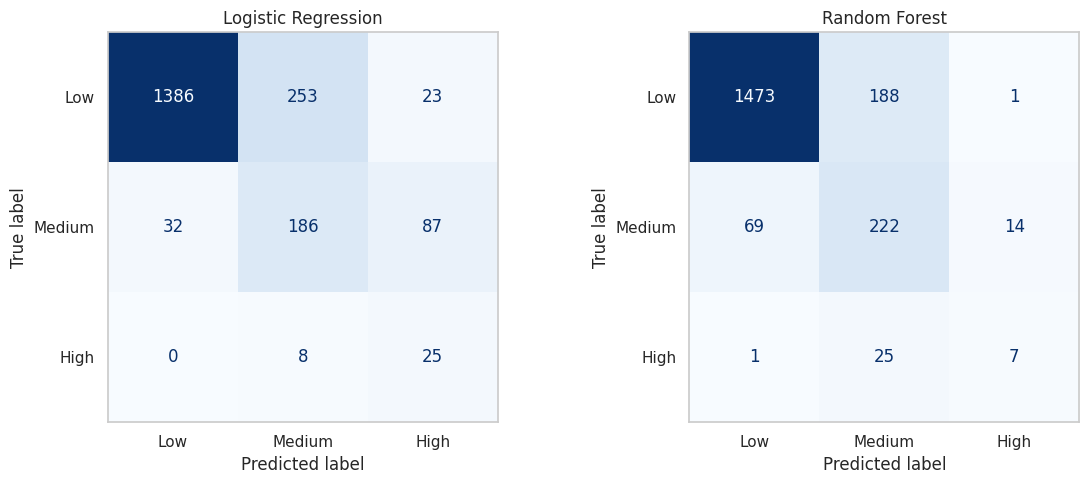

In [ ]:
# Classification report and confusion matrix for each model
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, preds3.items()):
    print(f"===== {name} =====")
    print(classification_report(y3_test, pred, labels=class_order, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y3_test, pred, labels=class_order),
                           display_labels=class_order).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

## 3.3 Factors influencing range anxiety
**Why:** besides prediction, we want to understand *what causes* higher anxiety. We use the Random Forest feature importance and look at the top factors directly in the data.

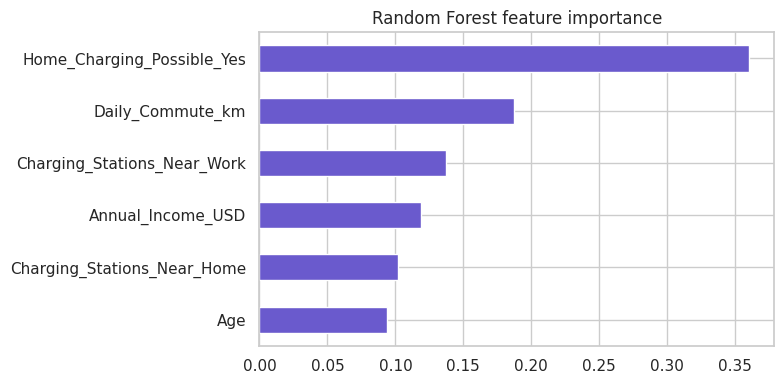

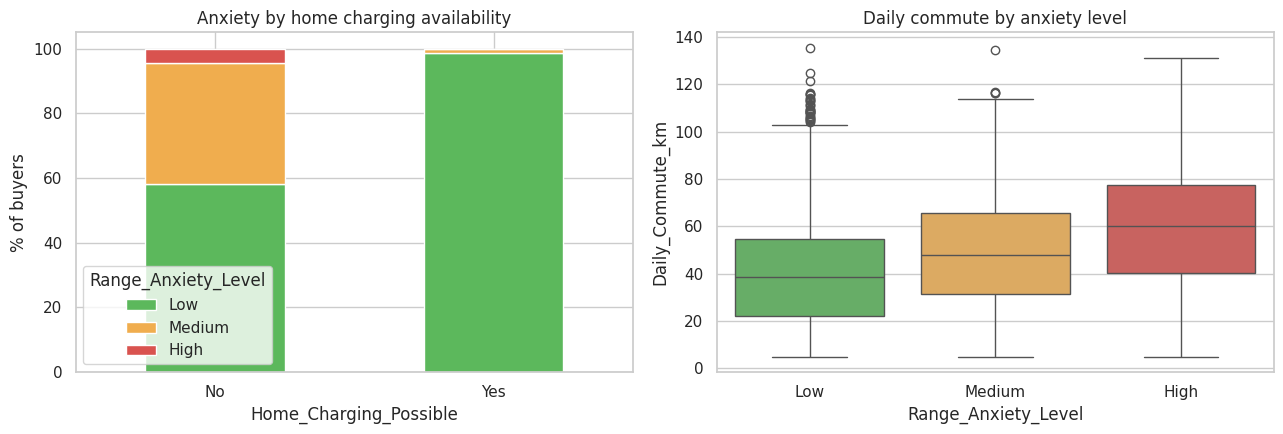

,Daily_Commute_km,Charging_Stations_Near_Home,Charging_Stations_Near_Work
Range_Anxiety_Level,,,
Low,39.36,5.37,7.59
Medium,48.44,5.42,7.04
High,60.15,3.57,4.46


In [ ]:
# Which selected features matter most to the Random Forest?
rf_imp3 = pd.Series(models3["Random Forest"].feature_importances_, index=selected).sort_values()
rf_imp3.plot(kind="barh", figsize=(8, 4), color="slateblue", title="Random Forest feature importance")
plt.tight_layout()
plt.show()

# Look at the top drivers directly in the data
colors = ["#5cb85c", "#f0ad4e", "#d9534f"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pd.crosstab(df["Home_Charging_Possible"], df["Range_Anxiety_Level"], normalize="index")[class_order].mul(100).plot(
    kind="bar", stacked=True, ax=axes[0], color=colors, rot=0)
axes[0].set_title("Anxiety by home charging availability")
axes[0].set_ylabel("% of buyers")

sns.boxplot(data=df, x="Range_Anxiety_Level", y="Daily_Commute_km", order=class_order, ax=axes[1], palette=colors)
axes[1].set_title("Daily commute by anxiety level")
plt.tight_layout()
plt.show()

# Average of the main numeric factors for each anxiety level
df.groupby("Range_Anxiety_Level")[["Daily_Commute_km", "Charging_Stations_Near_Home",
                                   "Charging_Stations_Near_Work"]].mean().reindex(class_order).round(2)

## 3.4 Results and discussion

**Test set results (2,000 buyers: 1,662 Low, 305 Medium, only 33 High)**

| Model | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|
| Logistic Regression | 0.798 | 0.526 | 0.734 | 0.564 |
| **Random Forest** | **0.828** | 0.564 | 0.656 | **0.592** |

* **Random Forest is the best model** by macro-F1 (0.592). **Low** is predicted very well (F1 0.91), **Medium** reasonably (F1 0.59), but **High** is hard (F1 0.29).
* **Errors are mostly between neighbouring levels.** In the confusion matrix, Low is almost never predicted as High (6 cases), and no High case was predicted as Low.
* **Why High is hard:** only 167 of 10,000 buyers (1.7%) are High, and just 33 in the test set, so the model has very few examples. Logistic Regression finds more High cases (recall 0.76) but with very low precision (0.19), so it raises many false alarms.
* **Feature selection** kept 6 of the 17 features: age, income, commute distance, both station counts and home charging. Age and income pass only because Random Forest importance favours continuous values, and they matter little in the data.

**Factors influencing range anxiety**
1. **Home charging is the dominant factor** (highest mutual information and importance). With home charging, **98.6%** have Low anxiety and none has High anxiety. Without it, 37% have Medium and 4% High anxiety. In fact 166 of the 167 High-anxiety buyers have no home charging.
2. **Daily commute distance:** longer drives mean higher anxiety (average about 39 km for Low, 48 km for Medium, 60 km for High), because long trips use more of the battery range.
3. **Public charging stations:** High-anxiety buyers have fewer stations near work (about 4.5 vs 7.6 for Low) and near home (3.6 vs 5.4). Without a home charger, public stations are the only backup.
4. **City type** matters mostly indirectly: urban residents more often lack home charging (Task 1.4).
5. **Gender, car type, cars owned, concern level and subsidy** were not selected, meaning they carry little information about anxiety.

**Practical implication:** the best way to reduce range anxiety, and so increase EV purchases (Task 2), is to help buyers get **home or workplace charging** and to build more **public charging** near homes and workplaces.

*Note: these are patterns in the data, not proof of cause and effect, and the High class is too small for firm conclusions.*

---
# Overall Conclusion

| Task | Main result |
|---|---|
| **1. EDA** | About 1.8% missing values in three columns, filled with the median. **City type strongly affects home charging** (rural 91%, suburban 80%, urban 40%). **Environmental concern is unrelated to income.** |
| **2. EV purchase** | Both models reach F1 about 0.62 with recall 0.80-0.87. Key drivers: **subsidy, environmental concern, income**. Range anxiety lowers purchase intention. |
| **3. Range anxiety** | Random Forest: accuracy 0.83, macro-F1 0.59. **Home charging is the dominant factor**, then commute distance and nearby public charging. The rare "High" class is hardest to predict. |

## Using our Machine Learning Models with Custom Data Input

In this section, we show how to utilize our trained models to predict both `Will_Buy_EV` and `Range_Anxiety_Level` for new, custom customer profiles.

We define a helper function to take raw demographic and behavioral input, format it correctly (including one-hot encoding columns to match our training dataset), and run predictions.

In [ ]:
def predict_custom_buyer(age, gender, annual_income, city_type, daily_commute, cars_owned, current_car,
                         stations_home, stations_work, home_charging, concern_level, subsidy):
    # Create a raw input DataFrame
    custom_raw = pd.DataFrame([{
        'Age': age,
        'Gender': gender,
        'Annual_Income_USD': annual_income,
        'City_Type': city_type,
        'Daily_Commute_km': daily_commute,
        'Number_of_Cars_Owned': cars_owned,
        'Current_Car_Type': current_car,
        'Charging_Stations_Near_Home': stations_home,
        'Charging_Stations_Near_Work': stations_work,
        'Home_Charging_Possible': home_charging,
        'Environmental_Concern_Level': concern_level,
        'Subsidy_Available': subsidy
    }])

    # Step A: Predict Range Anxiety Level (Task 3 Model requires selected features)
    # Prepare features for Task 3 input
    X3_custom = pd.get_dummies(custom_raw, drop_first=False)

    # Ensure all one-hot encoded columns from X3 match training columns
    for col in X3_train.columns:
        if col not in X3_custom.columns:
            X3_custom[col] = 0

    X3_custom_sel = X3_custom[selected]

    # Predict range anxiety level
    range_anxiety_pred = models3["Random Forest"].predict(X3_custom_sel)[0]

    # Step B: Predict EV Purchase Intention (Task 2 Model)
    # Append predicted range anxiety to the custom features as required by Task 2
    custom_raw_t2 = custom_raw.copy()
    custom_raw_t2['Range_Anxiety_Level'] = range_anxiety_pred

    # Map anxiety string values to numeric ordinals as done in training
    custom_raw_t2['Range_Anxiety_Level'] = custom_raw_t2['Range_Anxiety_Level'].map({"Low": 0, "Medium": 1, "High": 2})

    # One-hot encode remaining variables
    X2_custom = pd.get_dummies(custom_raw_t2, drop_first=False)

    # Ensure one-hot encoded columns match X2 training format
    for col in X2_train.columns:
        if col not in X2_custom.columns:
            X2_custom[col] = 0

    X2_custom_aligned = X2_custom[X2_train.columns]

    # Predict EV Purchase
    purchase_pred_num = models2["Random Forest"].predict(X2_custom_aligned)[0]
    purchase_pred = "Yes" if purchase_pred_num == 1 else "No"

    return {
        "Predicted Range Anxiety": range_anxiety_pred,
        "Predicted Will Buy EV": purchase_pred
    }

# Test Cases
profiles = [
    {
        "desc": "Profile 1: Rich, highly environmentally concerned, suburban commuter with home charging access & subsidy",
        "params": {
            "age": 40, "gender": "Female", "annual_income": 120000.0, "city_type": "Suburban",
            "daily_commute": 25.0, "cars_owned": 2, "current_car": "Sedan", "stations_home": 5,
            "stations_work": 8, "home_charging": "Yes", "concern_level": 5, "subsidy": "Yes"
        }
    },
    {
        "desc": "Profile 2: Long-distance urban commuter, no home charging or subsidies, low environmental concern",
        "params": {
            "age": 35, "gender": "Male", "annual_income": 55000.0, "city_type": "Urban",
            "daily_commute": 95.0, "cars_owned": 1, "current_car": "SUV", "stations_home": 2,
            "stations_work": 1, "home_charging": "No", "concern_level": 1, "subsidy": "No"
        }
    }
]

for p in profiles:
    print(f"=== {p['desc']} ===")
    res = predict_custom_buyer(**p['params'])
    for k, v in res.items():
        print(f"{k}: {v}")
    print()

=== Profile 1: Rich, highly environmentally concerned, suburban commuter with home charging access & subsidy ===
Predicted Range Anxiety: Low
Predicted Will Buy EV: Yes

=== Profile 2: Long-distance urban commuter, no home charging or subsidies, low environmental concern ===
Predicted Range Anxiety: High
Predicted Will Buy EV: No

